# Figure 4: dense obstacle course

Plans through a random course with 15,000 obstacles and compares the minimum-pressure path with the minimum-distance path.

**Runtime:** about 1.5 minutes to generate the course, then three timed solves of about 30 seconds each on an 8-core machine; slower on fewer cores.

In [1]:
import sys; sys.path.insert(0, "..")   # use the repo's vine_planner without pip install

import time

import numpy as np

from vine_planner.obstacle_course import ObstacleCourse
from vine_planner.path_planner import PathPlanner
from vine_planner.utils import path_metrics, path_pressure, pressure_conversion

PSI_TO_KPA = pressure_conversion("psi", "kpa")

In [2]:
course = ObstacleCourse.random(
    seed=46442304419989827214423540805172882445,
    num_obstacles=15_000, radius=0.0185, width=8, height=8,
)

In [3]:
# Time the algorithm from Section IV (visibility graph, line graph, minimum-pressure search).
# Numba compile time is excluded, and the reported time is the median of 3 runs.
# About 21 s builds the visibility graph; about 10 s is the search, which explores most of the
# line graph here because the goal needs a high-pressure path.
PathPlanner(ObstacleCourse.random(num_obstacles=20, seed=0), length_units="m").compute_pressure_path()   # warm-up

times = []
for _ in range(3):
    start = time.perf_counter()
    planner = PathPlanner(course, start=(2.2, 1.5), end=(5.25, 6.5), length_units="m")
    planner.compute_pressure_path()
    times.append(time.perf_counter() - start)

print("runs:", ", ".join(f"{t:.1f} s" for t in times), f"| median: {np.median(times):.1f} s")

runs: 32.8 s, 32.4 s, 32.9 s | median: 32.8 s


## Pressure, turning, and length of each path

Expected: minimum pressure is 318 kPa, 700°, 6.29 m; minimum distance is 19,430 kPa, about 1460°, 6.03 m.

In [4]:
planner.compute_distance_path()   # for comparison; not part of the timing above

for name, path in [("min pressure", planner.pressure_path), ("min distance", planner.distance_path)]:
    length, angle = path_metrics(path)
    pressure = path_pressure(path, length_units="m", **planner.model_parameters) * PSI_TO_KPA
    print(f"{name:<13} {pressure:8,.0f} kPa  {np.degrees(angle):5.0f}°  {length:.2f} m")

print(f"\nvisibility graph: {planner.vertex_count:,} vertices")
print(f"line graph:       {planner.edge_count:,} vertices, {planner.line_graph_arc_count:,} edges")

min pressure       318 kPa    700°  6.29 m
min distance    19,430 kPa   1461°  6.03 m

visibility graph: 54,712 vertices
line graph:       801,008 vertices, 12,738,916 edges


## Fig. 4

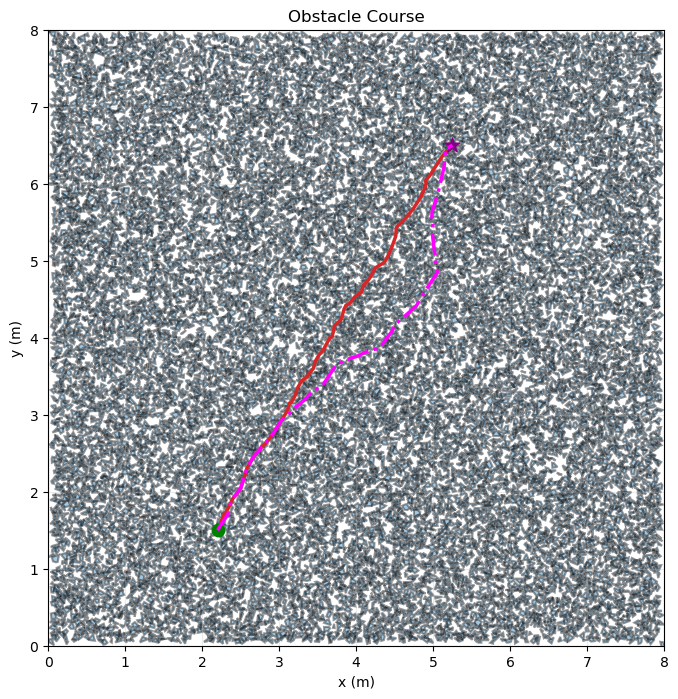

In [5]:
fig, ax = planner.plot(show_vertices=False, show_legend=False, length_units="m")